**SARIMAX**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
smax_params=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\sarimax_best_params.csv')
smax_co=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\sarimax_coefficients.csv')
smax_preds=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\SARIMAX_Media_Evals.csv')

In [5]:
smax_preds

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,SARIMAX,articles,1,0.064059,0.083882,-0.141441,35
1,Los Angeles,SARIMAX,articles,3,0.064710,0.081952,-0.167959,99
2,Los Angeles,SARIMAX,twitter,1,0.065001,0.082193,-0.095937,35
3,Los Angeles,SARIMAX,twitter,3,0.065038,0.080879,-0.137579,99
4,Los Angeles,SARIMAX,twitter,6,0.065639,0.081206,-0.146829,180
...,...,...,...,...,...,...,...,...
184,Merced,SARIMAX,articles,6,0.417809,0.555814,-0.088832,180
185,Merced,SARIMAX,articles,3,0.422822,0.544113,-0.092828,99
186,Merced,SARIMAX,all_media,1,0.429284,0.544322,-0.138780,35
187,Merced,SARIMAX,all_media,6,0.445464,0.587835,-0.217905,180


In [6]:
smax_co

,County,Feature_Set,Horizon,Split,Feature,Coefficient,P_Value
0,Alameda,all_media,1,1,mean_title_positive,43060.774158,0.000000
1,Alameda,all_media,1,1,mean_title_neutral,43060.810434,0.000000
2,Alameda,all_media,1,1,mean_title_negative,43060.722677,0.000000
3,Alameda,all_media,1,1,mean_title_sentiment,0.051532,0.433718
4,Alameda,all_media,1,1,mean_body_positive,-43060.817556,0.000000
...,...,...,...,...,...,...,...
90547,Ventura,twitter,6,30,max_risk,0.377464,0.350257
90548,Ventura,twitter,6,30,avg_risk,-3.024656,0.288815
90549,Ventura,twitter,6,30,tweet_count,0.002140,0.169616
90550,Ventura,twitter,6,30,avg_likes,0.005773,0.420303


In [8]:
best_rmse_by_county_horizon = smax_preds.loc[
    smax_preds.groupby(["County", "Horizon"])["RMSE"].idxmin()
].sort_values(["RMSE", "Horizon"]).reset_index(drop=True)

best_rmse_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,SARIMAX,twitter,3,0.065038,0.080879,-0.137579,99
1,Los Angeles,SARIMAX,twitter,6,0.065639,0.081206,-0.146829,180
2,Los Angeles,SARIMAX,twitter,1,0.065001,0.082193,-0.095937,35
3,San Diego,SARIMAX,articles,1,0.100290,0.118369,0.299026,35
4,Orange,SARIMAX,articles,1,0.098901,0.126101,0.178014,35
5,San Diego,SARIMAX,articles,3,0.106544,0.128222,0.183728,99
6,San Diego,SARIMAX,articles,6,0.108720,0.131808,0.162199,180
7,Orange,SARIMAX,articles,6,0.102495,0.133376,-0.055398,180
8,Orange,SARIMAX,articles,3,0.106028,0.136255,-0.029374,99
9,Riverside,SARIMAX,articles,1,0.133167,0.165642,0.250810,35


In [9]:
best_mae_by_county_horizon = smax_preds.loc[
    smax_preds.groupby(['County', 'Horizon'])['MAE'].idxmin()
].sort_values(['MAE', 'County']).reset_index(drop=True)

best_mae_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,SARIMAX,articles,1,0.064059,0.083882,-0.141441,35
1,Los Angeles,SARIMAX,articles,3,0.064710,0.081952,-0.167959,99
2,Los Angeles,SARIMAX,twitter,6,0.065639,0.081206,-0.146829,180
3,San Diego,SARIMAX,all_media,1,0.096551,0.120850,0.269331,35
4,Orange,SARIMAX,articles,1,0.098901,0.126101,0.178014,35
5,Orange,SARIMAX,articles,6,0.102495,0.133376,-0.055398,180
6,San Diego,SARIMAX,all_media,3,0.102668,0.129796,0.163564,99
7,San Diego,SARIMAX,all_media,6,0.105283,0.135529,0.114229,180
8,Orange,SARIMAX,articles,3,0.106028,0.136255,-0.029374,99
9,Riverside,SARIMAX,articles,1,0.133167,0.165642,0.250810,35


Los Angeles and San Diego produce the best RMSE and MAE's for all horizons, and Riverside has best RMSE and MAE for Horizon 1

In [10]:
# keys that identify a "winner" in the best-results table
smax_co=smax_co.rename(columns={'Feature_Set':'Feature Set'})

keys = ["County", "Horizon", "Feature Set"]

best_vals = best_rmse_by_county_horizon[keys + ["RMSE", "MAE"]].drop_duplicates(keys)

smax_best = smax_co.merge(best_vals, on=keys, how="inner")

In [11]:
smax_co.loc[smax_co['Feature Set']=='twitter']

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
3234,Alameda,twitter,1,1,min_sentiment,-0.128667,0.168689
3235,Alameda,twitter,1,1,max_sentiment,-0.127076,0.016880
3236,Alameda,twitter,1,1,avg_sentiment,0.129395,0.114169
3237,Alameda,twitter,1,1,avg_positive,0.062969,0.678075
3238,Alameda,twitter,1,1,avg_negative,-0.066426,0.594248
...,...,...,...,...,...,...,...
90547,Ventura,twitter,6,30,max_risk,0.377464,0.350257
90548,Ventura,twitter,6,30,avg_risk,-3.024656,0.288815
90549,Ventura,twitter,6,30,tweet_count,0.002140,0.169616
90550,Ventura,twitter,6,30,avg_likes,0.005773,0.420303


In [12]:
LA=smax_co.loc[smax_co['County']=='Los Angeles'].head(10)
LA.loc[LA['P_Value']<=.05]

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
17248,Los Angeles,all_media,1,1,mean_title_positive,299142.862946,0.0
17249,Los Angeles,all_media,1,1,mean_title_neutral,299142.931591,0.0
17250,Los Angeles,all_media,1,1,mean_title_negative,299142.884497,0.0
17252,Los Angeles,all_media,1,1,mean_body_positive,-299143.012002,0.0
17253,Los Angeles,all_media,1,1,mean_body_neutral,-299143.027648,0.0
17254,Los Angeles,all_media,1,1,mean_body_negative,-299142.988399,0.0


In [13]:
SD=smax_co.loc[smax_co['County']=='San Diego'].head(10)
SD.loc[SD['P_Value']<=.05]

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
47432,San Diego,all_media,1,1,mean_title_positive,-270048.022810,0.000000
47433,San Diego,all_media,1,1,mean_title_neutral,-270048.078668,0.000000
47434,San Diego,all_media,1,1,mean_title_negative,-270048.051031,0.000000
47436,San Diego,all_media,1,1,mean_body_positive,270048.050381,0.000000
47437,San Diego,all_media,1,1,mean_body_neutral,270048.087039,0.000000
47438,San Diego,all_media,1,1,mean_body_negative,270048.063104,0.000000
47441,San Diego,all_media,1,1,mean_body_risk,-1.698835,0.043506


In [14]:
Twitter=smax_co.loc[smax_co['Feature Set']=='twitter']
Twitter=Twitter.loc[Twitter['County']=='San Diego']
Twitter

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
50666,San Diego,twitter,1,1,min_sentiment,0.022780,0.810759
50667,San Diego,twitter,1,1,max_sentiment,-0.026853,0.609449
50668,San Diego,twitter,1,1,avg_sentiment,-0.001196,0.986057
50669,San Diego,twitter,1,1,avg_positive,0.023980,0.872718
50670,San Diego,twitter,1,1,avg_negative,0.025176,0.851542
...,...,...,...,...,...,...,...
51739,San Diego,twitter,6,30,max_risk,0.224077,0.165276
51740,San Diego,twitter,6,30,avg_risk,-0.420729,0.565934
51741,San Diego,twitter,6,30,tweet_count,0.000470,0.359976
51742,San Diego,twitter,6,30,avg_likes,0.003776,0.050596


In [15]:
near_sig=smax_co.loc[smax_co['P_Value']<=.059]
near_sig

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
0,Alameda,all_media,1,1,mean_title_positive,4.306077e+04,0.000000
1,Alameda,all_media,1,1,mean_title_neutral,4.306081e+04,0.000000
2,Alameda,all_media,1,1,mean_title_negative,4.306072e+04,0.000000
4,Alameda,all_media,1,1,mean_body_positive,-4.306082e+04,0.000000
5,Alameda,all_media,1,1,mean_body_neutral,-4.306086e+04,0.000000
...,...,...,...,...,...,...,...
89465,Ventura,articles,6,30,mean_title_negative,-1.112586e+06,0.000000
89466,Ventura,articles,6,30,mean_title_sentiment,2.589572e-01,0.033987
89467,Ventura,articles,6,30,mean_body_positive,1.112587e+06,0.000000
89468,Ventura,articles,6,30,mean_body_neutral,1.112586e+06,0.000000


In [16]:
R=smax_co.loc[smax_co['County']=='Riverside'].head(10)
R.loc[R['P_Value']<=.05]

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value
34496,Riverside,all_media,1,1,mean_title_positive,105933.220973,0.0
34497,Riverside,all_media,1,1,mean_title_neutral,105933.294394,0.0
34498,Riverside,all_media,1,1,mean_title_negative,105933.280988,0.0
34500,Riverside,all_media,1,1,mean_body_positive,-105933.209358,0.0
34501,Riverside,all_media,1,1,mean_body_neutral,-105933.232711,0.0
34502,Riverside,all_media,1,1,mean_body_negative,-105933.226809,0.0


All significant variables nearly cancel out, but lead to a positive gain for media signals at
.127477

All media feature sets are only significant. Why coefficients so big?

In [17]:
best_Smax = smax_best.loc[
    smax_best.groupby(['County', 'Horizon'])['MAE'].idxmin()
].sort_values(['MAE', 'County']).reset_index(drop=True)

best_Smax.head(10)

,County,Feature Set,Horizon,Split,Feature,Coefficient,P_Value,RMSE,MAE
0,Los Angeles,twitter,1,1,min_sentiment,0.020973,0.797246,0.082193,0.065001
1,Los Angeles,twitter,3,1,min_sentiment,0.020973,0.797246,0.080879,0.065038
2,Los Angeles,twitter,6,1,min_sentiment,0.020973,0.797246,0.081206,0.065639
3,Orange,articles,1,1,mean_title_positive,-99106.166278,0.000000,0.126101,0.098901
4,San Diego,articles,1,1,mean_title_positive,-213553.268377,0.000000,0.118369,0.100290
5,Orange,articles,6,1,mean_title_positive,-99106.166278,0.000000,0.133376,0.102495
6,Orange,articles,3,1,mean_title_positive,-99106.166278,0.000000,0.136255,0.106028
7,San Diego,articles,3,1,mean_title_positive,-213553.268377,0.000000,0.128222,0.106544
8,San Diego,articles,6,1,mean_title_positive,-213553.268377,0.000000,0.131808,0.108720
9,Riverside,articles,1,1,mean_title_positive,187286.707942,0.000000,0.165642,0.133167


**Random Forest**

In [18]:
forest_params=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\random_forest_best_params.csv')
forest_co=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\random_forest_feature_importance.csv')
forest_vals=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\RandForest_Media_Model_Evals.csv')

In [19]:
fbest_rmse_by_county_horizon = forest_vals.loc[
    forest_vals.groupby(["County", "Horizon"])["RMSE"].idxmin()
].sort_values(["RMSE", "Horizon"]).reset_index(drop=True)

fbest_rmse_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,RandForest,twitter,6,0.065273,0.080578,-0.129160,180
1,Los Angeles,RandForest,twitter,3,0.065295,0.080688,-0.132217,99
2,Los Angeles,RandForest,twitter,1,0.067887,0.083734,-0.137428,35
3,Orange,RandForest,articles,6,0.102737,0.134737,-0.077036,180
4,San Diego,RandForest,all_media,1,0.114715,0.139131,0.031550,35
5,San Diego,RandForest,all_media,3,0.114280,0.139614,0.032239,99
6,Orange,RandForest,twitter,3,0.106782,0.139724,-0.082455,99
7,San Diego,RandForest,all_media,6,0.116684,0.141654,0.032363,180
8,Orange,RandForest,twitter,1,0.112794,0.144618,-0.081114,35
9,Fresno,RandForest,articles,6,0.137828,0.162771,-0.037391,180


In [11]:
fbest_mae_by_county_horizon = forest_vals.loc[
    forest_vals.groupby(['County', 'Horizon'])['MAE'].idxmin()
].sort_values(['MAE', 'County']).reset_index(drop=True)

fbest_mae_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,RandForest,twitter,6,0.065273,0.080578,-0.129160,180
1,Los Angeles,RandForest,twitter,3,0.065295,0.080688,-0.132217,99
2,Los Angeles,RandForest,twitter,1,0.067887,0.083734,-0.137428,35
3,Orange,RandForest,all_media,6,0.101119,0.136548,-0.106193,180
4,Orange,RandForest,all_media,3,0.106148,0.140752,-0.098436,99
5,Orange,RandForest,all_media,1,0.110908,0.146546,-0.110132,35
6,San Diego,RandForest,all_media,3,0.114280,0.139614,0.032239,99
7,San Diego,RandForest,all_media,1,0.114715,0.139131,0.031550,35
8,San Diego,RandForest,all_media,6,0.116684,0.141654,0.032363,180
9,San Bernardino,RandForest,twitter,1,0.130882,0.216833,-0.060111,35


What doesn't match: Fresno is only present amoung the best RMSE scores, Orange County feature sets vary with best RMSE but are consistent across MAE, San Bernadino is present among only best MAE scores. R2 remains horrid

MAE and RMSE stay within the same range between .06 and .13

Random Forest appears to do a better job at predictions across all horizons compared to SARIMAX

In [20]:
# keys that identify a "winner" in the best-results table
forest_co=forest_co.rename(columns={'Feature_Set':'Feature Set'})

keys = ["County", "Horizon", "Feature Set"]

best_vals = fbest_rmse_by_county_horizon[keys + ["RMSE", "MAE"]].drop_duplicates(keys)

forest_best = forest_co.merge(best_vals, on=keys, how="inner")

In [21]:
SB=forest_co.loc[forest_co['County']=='San Bernardino']
SB=SB.loc[SB['Feature Set']=='twitter']
SB=SB.loc[SB['Horizon']==1]
SB.sort_values(by='Importance', ascending=False)

,County,Feature Set,Horizon,Split,Feature,Importance
46639,San Bernardino,twitter,1,25,total_likes,0.155286
46464,San Bernardino,twitter,1,10,min_sentiment,0.153638
46650,San Bernardino,twitter,1,26,total_likes,0.152987
46628,San Bernardino,twitter,1,24,total_likes,0.149382
46453,San Bernardino,twitter,1,9,min_sentiment,0.148838
...,...,...,...,...,...,...
46733,San Bernardino,twitter,1,34,min_risk,0.000237
46359,San Bernardino,twitter,1,0,min_risk,0.000230
46447,San Bernardino,twitter,1,8,min_risk,0.000230
46645,San Bernardino,twitter,1,26,min_risk,0.000216


In [24]:
LA=forest_co.loc[forest_co['County']=='Los Angeles']
LA=LA.loc[LA['Feature Set']=='twitter']
LA.sort_values(by='Importance',ascending=False).head(10)

,County,Feature Set,Horizon,Split,Feature,Importance
20563,Los Angeles,twitter,1,7,avg_negative,0.135961
21311,Los Angeles,twitter,6,7,avg_negative,0.135961
20948,Los Angeles,twitter,3,7,avg_negative,0.135961
20519,Los Angeles,twitter,1,3,avg_negative,0.135653
20904,Los Angeles,twitter,3,3,avg_negative,0.135653
21267,Los Angeles,twitter,6,3,avg_negative,0.135653
20486,Los Angeles,twitter,1,0,avg_negative,0.135543
21234,Los Angeles,twitter,6,0,avg_negative,0.135543
20871,Los Angeles,twitter,3,0,avg_negative,0.135543
20915,Los Angeles,twitter,3,4,avg_negative,0.134734


Across all horizons and splits the avg negative sentiment of tweets held the highest featue importance in the twitter model with the best MAE/RMSE

In [23]:
O=forest_co.loc[forest_co['County']=='Orange']
O.sort_values(by='Importance',ascending=False).head(10)

,County,Feature Set,Horizon,Split,Feature,Importance
32503,Orange,articles,1,14,mean_body_risk,0.163389
33251,Orange,articles,6,14,mean_body_risk,0.163389
32888,Orange,articles,3,14,mean_body_risk,0.163389
32877,Orange,articles,3,13,mean_body_risk,0.159163
33240,Orange,articles,6,13,mean_body_risk,0.159163
32492,Orange,articles,1,13,mean_body_risk,0.159163
32459,Orange,articles,1,10,mean_body_risk,0.152507
33207,Orange,articles,6,10,mean_body_risk,0.152507
32844,Orange,articles,3,10,mean_body_risk,0.152507
32866,Orange,articles,3,12,mean_body_risk,0.152326


In [29]:
OT=O.loc[O['Feature Set']=='twitter']
OT=OT.loc[OT['Horizon']==1]
OT.sort_values(by='Importance',ascending=False).head(10)

,County,Feature Set,Horizon,Split,Feature,Importance
33619,Orange,twitter,1,18,avg_positive,0.130882
33608,Orange,twitter,1,17,avg_positive,0.127568
33630,Orange,twitter,1,19,avg_positive,0.127151
33432,Orange,twitter,1,1,avg_positive,0.126747
33454,Orange,twitter,1,3,avg_positive,0.124893
33597,Orange,twitter,1,16,avg_positive,0.123605
33586,Orange,twitter,1,15,avg_positive,0.123305
33421,Orange,twitter,1,0,avg_positive,0.122612
33553,Orange,twitter,1,12,avg_positive,0.121501
33465,Orange,twitter,1,4,avg_positive,0.118614


In [30]:
OM=O.loc[O['Feature Set']=='all_media']
OM.sort_values(by='Importance',ascending=False).head(10)

,County,Feature Set,Horizon,Split,Feature,Importance
31975,Orange,all_media,6,13,mean_body_risk,0.085108
31249,Orange,all_media,3,13,mean_body_risk,0.085108
30479,Orange,all_media,1,13,mean_body_risk,0.085108
30501,Orange,all_media,1,14,mean_body_risk,0.081259
31997,Orange,all_media,6,14,mean_body_risk,0.081259
31271,Orange,all_media,3,14,mean_body_risk,0.081259
31953,Orange,all_media,6,12,mean_body_risk,0.080698
30457,Orange,all_media,1,12,mean_body_risk,0.080698
31227,Orange,all_media,3,12,mean_body_risk,0.080698
31821,Orange,all_media,6,6,mean_body_risk,0.079216


Across all best models by RMSE and MAE, the highest feature importance for Orange County was mean body risk of articles, across all splits where the horizon was one in the twitter feature set, the average positive sentiment of tweers has the highest feature importance. Across all horizons where all media is the feature set the most important feature in mean body risk 

**Create code that makes it so for every horizon it gives an RMSE/MAE improvement for counties in model**

In [22]:
x_params=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\xgboost_best_params.csv')
x_evals=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\xgboost_Media_Evals.csv')
x_features=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Evals\xgboost_feature_importance.csv')

In [52]:
xbest_rmse_by_county_horizon = x_evals.loc[
    x_evals.groupby(["County", "Horizon"])["RMSE"].idxmin()
].sort_values(["RMSE", "Horizon"]).reset_index(drop=True)

xbest_rmse_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
0,Los Angeles,XGBoost,all_media,3,0.062043,0.076656,-0.021877,99
1,Los Angeles,XGBoost,twitter,6,0.061834,0.077015,-0.031508,180
2,Los Angeles,XGBoost,all_media,1,0.064655,0.078699,-0.004742,35
3,Orange,XGBoost,articles,6,0.099268,0.130358,-0.008170,180
4,Orange,XGBoost,articles,3,0.104037,0.135698,-0.020971,99
5,San Diego,XGBoost,articles,1,0.116655,0.141065,0.004435,35
6,Orange,XGBoost,articles,1,0.108337,0.141179,-0.030303,35
7,San Diego,XGBoost,articles,3,0.116896,0.141428,0.006914,99
8,San Diego,XGBoost,articles,6,0.118230,0.143375,0.008702,180
9,Fresno,XGBoost,articles,1,0.131737,0.162397,-0.115005,35


In [53]:
xbest_mae_by_county_horizon = x_evals.loc[
    x_evals.groupby(['County', 'Horizon'])['MAE'].idxmin()
].sort_values(['Horizon', 'MAE', 'County']).reset_index(drop=True)

top10_counties_by_horizon = (
    xbest_mae_by_county_horizon
    .groupby('Horizon')
    .head(10)
)

top10_counties_by_horizon.sort_values(by='County')

# xbest_mae_by_county_horizon.head(10)

,County,Model,Feature Set,Horizon,MAE,RMSE,R2,N Predictions
47,Alameda,XGBoost,articles,6,0.153197,0.196131,0.040973,180
28,Alameda,XGBoost,articles,3,0.156976,0.199693,0.051243,99
7,Alameda,XGBoost,articles,1,0.157478,0.198843,0.041169,35
51,Contra Costa,XGBoost,articles,6,0.163593,0.212088,-0.005663,180
46,Fresno,XGBoost,articles,6,0.138888,0.164172,-0.055323,180
25,Fresno,XGBoost,articles,3,0.136128,0.163894,-0.100110,99
4,Fresno,XGBoost,articles,1,0.131737,0.162397,-0.115005,35
48,Kern,XGBoost,articles,6,0.154179,0.186580,0.004011,180
26,Kern,XGBoost,articles,3,0.150580,0.184477,-0.015009,99
5,Kern,XGBoost,articles,1,0.144405,0.179462,0.005417,35


XGBoost has 

In [23]:
lstm_preds=pd.read_csv(r'C:\Users\zions\Cocci\ValleyFever-MediaSignals\results\media\Predictions\LSTM_predictions.csv')

In [4]:
lstm_preds

,split,lead,actual,predicted,County,Feature_Set,Horizon
0,0,1,0.120033,0.014941,Alameda,all_media,1
1,1,1,-0.208890,0.001002,Alameda,all_media,1
2,2,1,-0.097529,0.013188,Alameda,all_media,1
3,3,1,0.510353,-0.008211,Alameda,all_media,1
4,4,1,-0.242367,0.008366,Alameda,all_media,1
...,...,...,...,...,...,...,...
19777,29,2,0.033578,0.048334,Ventura,twitter,6
19778,29,3,0.000000,0.022235,Ventura,twitter,6
19779,29,4,0.234410,0.027296,Ventura,twitter,6
19780,29,5,0.330601,0.022824,Ventura,twitter,6


In [24]:
# county_preds = {}

# for (county, horizon), df in lstm_preds.groupby(['County', 'Horizon']):
#     county_preds[(county, horizon)] = df
#     county_preds[county] = lstm_preds[
#         lstm_preds['County'] == county
#     ]
#     county_preds[county, horizon] = county_preds[
#         county_preds['Horizon'] == horizon
#     ]

county_preds = {}

for county, county_df in lstm_preds.groupby('County'):
    county_preds[county] = {}

    for horizon, horizon_df in county_df.groupby('Horizon'):
        county_preds[county][horizon] = {}

        for feature_set, feature_set_df in horizon_df.groupby('Feature_Set'):
            county_preds[county][horizon][feature_set] = feature_set_df




In [25]:
county_preds['Alameda'][6]['twitter']

,split,lead,actual,predicted,County,Feature_Set,Horizon
762,0,1,0.120033,0.028842,Alameda,twitter,6
763,0,2,-0.208890,0.044771,Alameda,twitter,6
764,0,3,-0.097529,0.046618,Alameda,twitter,6
765,0,4,0.510353,0.012044,Alameda,twitter,6
766,0,5,-0.242367,-0.010055,Alameda,twitter,6
...,...,...,...,...,...,...,...
937,29,2,0.269673,0.119212,Alameda,twitter,6
938,29,3,-0.226403,0.070759,Alameda,twitter,6
939,29,4,0.226403,0.025937,Alameda,twitter,6
940,29,5,0.126693,-0.044441,Alameda,twitter,6


In [26]:
import matplotlib.pyplot as plt

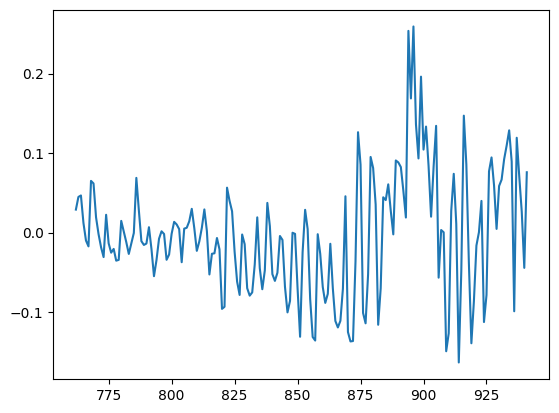

In [ ]:
plt.plot(county_preds['Alameda'][6]['twitter']['predicted'],
dates)

In [48]:
lstm_preds[['County', 'Horizon', 'split', 'lead', 'actual', 'predicted']].head(15)

,County,Horizon,split,lead,actual,predicted
0,Alameda,1,0,1,0.120033,0.014941
1,Alameda,1,1,1,-0.208890,0.001002
2,Alameda,1,2,1,-0.097529,0.013188
3,Alameda,1,3,1,0.510353,-0.008211
4,Alameda,1,4,1,-0.242367,0.008366
5,Alameda,1,5,1,-0.081601,0.001213
6,Alameda,1,6,1,-0.136432,-0.002491
7,Alameda,1,7,1,-0.102533,-0.018968
8,Alameda,1,8,1,0.052580,-0.010037
9,Alameda,1,9,1,0.343428,-0.015983


In [49]:
lstm_preds.groupby(
    ['County', 'Horizon', 'split']
).agg(
    n_predictions=('predicted', 'size'),
    min_lead=('lead', 'min'),
    max_lead=('lead', 'max')
).head(20)

n_predictions  min_lead  max_lead
County  Horizon split                                   
Alameda 1       0                  3         1         1
                1                  3         1         1
                2                  3         1         1
                3                  3         1         1
                4                  3         1         1
                5                  3         1         1
                6                  3         1         1
                7                  3         1         1
                8                  3         1         1
                9                  3         1         1
                10                 3         1         1
                11                 3         1         1
                12                 3         1         1
                13                 3         1         1
                14                 3         1         1
                15                 3         1         1
                16                 3         1         1
                17                 3         1         1
                18                 3         1         1
                19                 3         1         1

In [50]:
lstm_preds.groupby(
    ['Horizon', 'split']
)['lead'].nunique()

Horizon  split
1        0        1
         1        1
         2        1
         3        1
         4        1
                 ..
6        25       6
         26       6
         27       6
         28       6
         29       6
Name: lead, Length: 98, dtype: int64

In [ ]:
plt.plot(
    
)